# Characterising an exomoon with simultaneous GP detrending

The usual way to fit a moon is in two steps: first remove the star's variability with a filter (e.g. a robust
`biweight` in `wotan`), then fit the transit model to the flattened light curve with white-noise errors. For moons
this has a weak point. The filter must not see the transit, or it would remove part of it, so the transit is
**masked** while the trend is estimated. A moon can transit hours before or after the planet, so the mask has to
cover the planet's transit **and the moon's reach**, and the filter window has to be longer still. Inside this long
masked section the trend is not measured at all: it is interpolated from the data on either side. Whatever the star
does inside the mask stays in the "detrended" data, where it looks like, or hides, a moon.

The alternative is to fit the star and the transit **together**: the light curve is modelled as

    flux = transit model (planet + moon) + stellar variability (a Gaussian process) + white noise

and the stellar variability is integrated out. Its trend is then constrained by **all** data, including those
during the transit, and the transit model is fitted to the data as they are. Pandora does this with
`Likelihood(..., gp=GP(amp, tau, err_scale))`:

- the GP is the stochastically driven, damped harmonic oscillator kernel (SHO, Q = 1/√2; Foreman-Mackey et al. 2017),
  the same as in `pizzetti`: a smooth correlated signal of rms `amp` and time scale `tau`, plus white noise
  `err_scale × flux_err`;
- its likelihood is computed exactly with a Kalman filter, O(N) per call (TLS 2 and pizzetti use the same method);
- the three hyperparameters are **fixed** during the fit. You estimate them first, by maximum likelihood on the data
  outside the transits (`GP.fit`);
- it works on the CPU and on the GPU, for the planet+moon and the planet-only model (the Bayes factor compares both
  under the same noise model).

This notebook runs on the GPU (`device="gpu"`), where the fits take a few minutes; with `device="cpu"` the same code
runs on the CPU (the GP likelihoods of both devices agree to ~10^-3 nats).

In [1]:
%matplotlib inline
import time as timer
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['figure.figsize'] = [12, 4]

import pandoramoon as pandora
from pandoramoon.gp import GP
from pandoramoon.search import model_flux
DEVICE = "gpu"          # or "cpu": the same fits, slower

## 1. The system: a Neptune-size moon (Pandora paper, Fig. 4)

A Jupiter-mass planet (0.1 stellar radii) on a one-year orbit around a Sun-like star, with a Neptune-size moon
(0.035 stellar radii, a dip of ~1250 ppm) on a 1.28-day orbit. Four transits, each observed for 2 days at a 10-min
cadence, with 100 ppm white noise per point. We simulate it twice: with the moon, and without it (the planet only).
The second light curve is the important control: a good method must **not** find a moon there.

In [2]:
R_sun = 696_342_000  # [m]

def make_system(with_moon=True):
    params = pandora.model_params()
    params.R_star = R_sun
    params.u1, params.u2 = 0.4089, 0.2556
    params.per_bary = 365.25                 # [d]
    params.a_bary = 215                      # [stellar radii]
    params.r_planet = 0.1                    # [stellar radii]
    params.b_bary = 0.3
    params.t0_bary = 20.0                    # first transit [d]
    params.t0_bary_offset = 0.01
    params.M_planet = 1.8986e27              # [kg], 1 Jupiter mass
    params.w_bary, params.ecc_bary = 0, 0
    if with_moon:
        params.r_moon = 24622e3 / R_sun      # Neptune's radius [stellar radii]
        params.per_moon = 1.28               # [d]
        params.tau_moon = 0.3
        params.Omega_moon = 0.0
        params.i_moon = 80.0
        params.M_moon = 0.05395 * params.M_planet
    else:
        params.r_moon, params.per_moon, params.tau_moon = 1e-8, 30.0, 0.0
        params.Omega_moon, params.i_moon, params.M_moon = 0.0, 0.0, 1e-8
    params.ecc_moon, params.w_moon = 0, 0
    params.epochs = 4
    params.epoch_duration = 2.0              # [d] of data around each transit
    params.cadences_per_day = 144            # 10-min cadence
    params.epoch_distance = params.per_bary + 0.01
    params.supersampling_factor = 1
    params.occult_small_threshold = 0
    params.hill_sphere_threshold = 1.2
    return params

params = make_system(True)
T14 = params.per_bary / np.pi * np.arcsin(np.sqrt((1 + params.r_planet) ** 2 - params.b_bary ** 2) / params.a_bary)
t_tr = params.t0_bary + params.t0_bary_offset + params.per_bary * np.arange(params.epochs)
print(f"T14 = {24 * T14:.1f} h; moon dip ~ {1e6 * params.r_moon ** 2:.0f} ppm")

T14 = 13.7 h; moon dip ~ 1250 ppm


## 2. Stellar variability that needs detrending

We add two kinds of variability that real stars show:

1. **Rotation:** spots on a star rotating in 6 days: a quasi-periodic signal with amplitudes of 1500 and 600 ppm
   (fundamental and first harmonic). Over a 2-day window it is a strong curvature, larger than the moon's dip.
2. **Granulation-like correlated noise:** 200 ppm with a time scale of 0.15 days (3.6 hours), close to the moon's
   own time scale. We draw it with `GP(amp, tau).sample(time)`.

The GP model we fit later is a single SHO term: it describes neither component exactly, as with a real star.

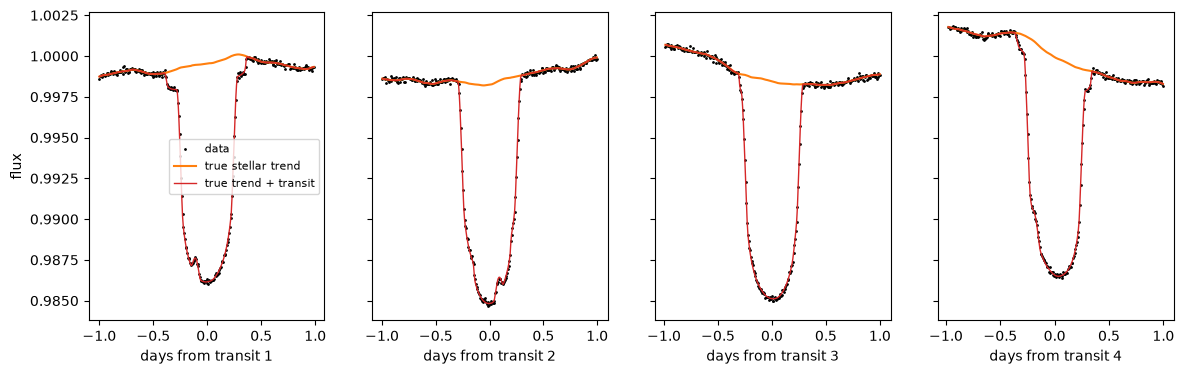

In [3]:
def simulate(with_moon, seed=0):
    p = make_system(with_moon)
    t = pandora.time(p).grid()
    flux_model, _, _ = pandora.moon_model(p).light_curve(t)
    rng = np.random.default_rng(1000 + seed)
    ph1, ph2 = rng.uniform(0, 2 * np.pi, 2)
    rotation = 1500e-6 * np.sin(2 * np.pi * t / 6.0 + ph1) + 600e-6 * np.sin(4 * np.pi * t / 6.0 + ph2)
    granulation = GP(200e-6, 0.15).sample(t, rng)
    trend = rotation + granulation
    flux = np.asarray(flux_model) + trend + rng.normal(0, 100e-6, len(t))
    return np.asarray(t), flux, np.full(len(t), 100e-6), np.asarray(flux_model), trend

time, flux, flux_err, flux_model, trend_true = simulate(True)
time0, flux0, flux_err0, flux_model0, trend_true0 = simulate(False)

fig, axs = plt.subplots(1, 4, sharey=True, figsize=(14, 4))
for k, ax in enumerate(axs):
    m = np.abs(time - t_tr[k]) < 1.0
    ax.plot(time[m] - t_tr[k], flux[m], ".", ms=2, color="k", label="data")
    ax.plot(time[m] - t_tr[k], 1 + trend_true[m], color="C1", label="true stellar trend")
    ax.plot(time[m] - t_tr[k], flux_model[m] + trend_true[m], color="C3", lw=1, label="true trend + transit")
    ax.set_xlabel(f"days from transit {k + 1}")
axs[0].set_ylabel("flux"); axs[0].legend(fontsize=8)
plt.show()

## 3. The classical route: biweight detrending with a masked transit

`wotan`'s biweight with the transits masked. The mask must cover the planet's transit (T14 = 13.7 h) **and** the
moon's reach: the moon is up to ~0.13 days (3 h) from the planet on the sky-projected orbit. We mask ±0.5 days
around each transit and use a 1.5-day window (it must be longer than the mask, and the data cover only 2 days per
transit). Inside the mask, the biweight trend is interpolated from the data on either side.

For the white-noise fit of the flattened data we need error bars. We use the two common choices:

- **σ**: the white noise (100 ppm, which we know here);
- **σ × β**: inflated by the red-noise factor β, measured on the flattened data outside the mask (bins of T14/4,
  as `prepare_lightcurve` does). This is the honest choice when residual trends remain.

In [4]:
from wotan import flatten
MASK_HALF = 0.5        # [d]
WINDOW = 1.5           # [d]

def biweight(time, flux):
    mask = np.min(np.abs(time[:, None] - t_tr[None, :]), axis=1) < MASK_HALF
    flat, trend = flatten(time, flux, method="biweight", window_length=WINDOW, return_trend=True, mask=mask)
    return flat, trend, mask

def red_noise_beta(time, flat, mask, sigma):
    r = flat[~mask & np.isfinite(flat)] - 1
    tt = time[~mask & np.isfinite(flat)]
    key = np.floor((tt - tt.min()) / (T14 / 4)).astype(int)
    _, inv, cnt = np.unique(key, return_inverse=True, return_counts=True)
    ok = cnt >= 3
    binned = np.bincount(inv, weights=r)[ok] / cnt[ok]
    return max(1.0, float(np.sqrt(np.mean(binned ** 2 / (sigma ** 2 / cnt[ok])))))

flat, trend_bw, mask = biweight(time, flux)
flat0, trend_bw0, _ = biweight(time0, flux0)
beta = red_noise_beta(time, flat, mask, 100e-6)
beta0 = red_noise_beta(time0, flat0, mask, 100e-6)
err_trend = trend_bw - (1 + trend_true)
print(f"red-noise factor beta = {beta:.2f} (moon light curve), {beta0:.2f} (planet only)")
print(f"biweight trend error: rms {1e6 * np.nanstd(err_trend[~mask]):.0f} ppm outside the mask, "
      f"{1e6 * np.nanstd(err_trend[mask]):.0f} ppm inside (the moon's dip: 1250 ppm)")

red-noise factor beta = 7.37 (moon light curve), 7.37 (planet only)
biweight trend error: rms 183 ppm outside the mask, 643 ppm inside (the moon's dip: 1250 ppm)


## 4. The simultaneous GP

First the hyperparameters, by maximum likelihood on the same out-of-mask data (`mask=True` leaves a point out).
`GP.fit` follows TLS 2's fit of its GP baselines: the exact gradient of the Kalman likelihood and a bounded
quasi-Newton optimiser, with transitions computed once per distinct time step. It takes milliseconds. Then the
likelihood of the **raw** light curve with the GP.

In [5]:
t0 = timer.time()
gp = GP.fit(time, flux, flux_err, mask=mask)
gp0 = GP.fit(time0, flux0, flux_err0, mask=mask)
print(f"GP.fit: {1e3 * (timer.time() - t0) / 2:.1f} ms each")
print("moon light curve:  ", gp)
print("planet-only curve: ", gp0)

# how well does the GP know the trend inside the mask from the data outside it alone?
mu, sd = gp.predict(time, flux - 1.0, flux_err, mask=mask)
print(f"GP trend from out-of-mask data only: error rms {1e6 * np.std((mu - trend_true)[mask]):.0f} ppm inside "
      f"the mask, its own uncertainty {1e6 * np.mean(sd[mask]):.0f} ppm")

GP.fit: 5.9 ms each
moon light curve:   GP(amp=0.00120715, tau=0.545284, err_scale=0.981062)
planet-only curve:  GP(amp=0.00120715, tau=0.545284, err_scale=0.981062)
GP trend from out-of-mask data only: error rms 280 ppm inside the mask, its own uncertainty 277 ppm


Inside the mask the biweight's trend is off by 643 ppm rms, half the moon's dip. It is not even an interpolation:
near mid-transit wotan's window holds only data from one side or the other, so its robust estimate jumps from the
left side's level to the right side's (the figure in section 6 shows it). The flattened data keep that error, and
the white-noise fit treats it as signal. From the out-of-mask data alone the GP does better (280 ppm) and also knows
its uncertainty there (277 ppm). In the joint fit the data inside the mask constrain the trend together with the
transit model.

Both light curves get the same GP hyperparameters and the same β. They have the same star and noise, and differ
only inside the masked windows, where the moon is.

## 5. The fits

Six fits on the same footing (default priors, `accuracy="medium"`), each for the moon light curve and for the
planet-only light curve:

| | data | errors | noise model |
|---|---|---|---|
| biweight σ | biweight-flattened | σ = 100 ppm | white |
| biweight σβ | biweight-flattened | σ × β | white |
| GP | raw | 100 ppm × err_scale | GP + white |

The two "biweight σ" fits use `rules="r25"`, the sampler's escalation rules before Pandora's current default
`r26`. Their noise model is wrong on purpose: the flattened data keep residual trends of several hundred ppm, while
the error bars are 100 ppm. The runs then disagree with each other as if they had missed modes. The default rules
keep doubling the live points to 2000 and then lengthen the chains, and one such fit took more than 30 minutes on
the GPU. With `r25` the fit stops at 2000 live points, which is enough to show what it finds. The printed status
says whether each fit passed its own checks. A fit that did not pass is still usable, but its ln Z error is not
guaranteed (see `Fitting.rst`).

In [6]:
priors = pandora.default_priors(t0_bary=params.t0_bary, per_bary=params.per_bary, r_planet=params.r_planet)
truth = dict(r_moon=params.r_moon, per_moon=params.per_moon, r_planet=params.r_planet)

def fit(label, time, flux, err, gp=None, **kw):
    like = pandora.Likelihood(time, flux, err, epoch_distance=params.epoch_distance, hill_sphere_threshold=1.0, gp=gp)
    s = pandora.NestedSampler(like, priors, device=DEVICE, verbose=False, log_dir="results_gp/" + label,
                              resume="overwrite")
    t0 = timer.time()
    r = s.run(**kw)
    r["wall_total"] = timer.time() - t0
    r["sampler"] = s
    print(f"{label:26s} dlnZ {r['dlogz']:9.2f} +- {r['dlogzerr']:.2f}  {r['status']:8s} nsteps {r['nsteps']:3d} "
          f"n_live {r['nlive']:4d}  planet+moon fit {r['wall']:5.0f} s, total {r['wall_total']:5.0f} s", flush=True)
    return r

R = {}
R["biweight σ, moon"] = fit("bw_sigma_moon", time, flat, flux_err, rules="r25")
R["biweight σβ, moon"] = fit("bw_sigmabeta_moon", time, flat, flux_err * beta)
R["GP, moon"] = fit("gp_moon", time, flux, flux_err, gp=gp)
R["biweight σ, no moon"] = fit("bw_sigma_nomoon", time0, flat0, flux_err0, rules="r25")
R["biweight σβ, no moon"] = fit("bw_sigmabeta_nomoon", time0, flat0, flux_err0 * beta0)
R["GP, no moon"] = fit("gp_nomoon", time0, flux0, flux_err0, gp=gp0)

Pandora: compiling numerical code (first use after installation or an update can take a few minutes; the result is cached) ...


bw_sigma_moon              dlnZ   7984.69 +- 0.28  run_cap  nsteps  64 n_live 2000  planet+moon fit  1546 s, total  1606 s


bw_sigmabeta_moon          dlnZ    118.74 +- 0.20  stalled  nsteps 256 n_live 2000  planet+moon fit  2918 s, total  2952 s


Pandora: compiling numerical code (first use after installation or an update can take a few minutes; the result is cached) ...


Pandora: compiling numerical code (first use after installation or an update can take a few minutes; the result is cached) ...


gp_moon                    dlnZ   1494.60 +- 0.09  run_cap  nsteps  64 n_live  500  planet+moon fit   381 s, total   399 s


bw_sigma_nomoon            dlnZ   7903.26 +- 0.14  passed   nsteps  64 n_live 1000  planet+moon fit   311 s, total   325 s


bw_sigmabeta_nomoon        dlnZ    115.12 +- 0.12  passed   nsteps 128 n_live  500  planet+moon fit   200 s, total   207 s


gp_nomoon                  dlnZ     -5.00 +- 0.07  passed   nsteps  64 n_live 1000  planet+moon fit   497 s, total   506 s


In [7]:
def q(r, name):
    i = list(r["paramnames"]).index(name)
    return np.percentile(r["samples"][:, i], [15.87, 50, 84.13])

print(f"{'fit':24s} {'Delta ln Z':>11s}   {'r_moon (true %.4f)' % truth['r_moon']:>26s}   "
      f"{'per_moon [d] (true %.2f)' % truth['per_moon']:>26s}")
for k, r in R.items():
    a, b = q(r, "r_moon"), q(r, "per_moon")
    print(f"{k:24s} {r['dlogz']:11.2f}   {a[1]:.4f} ({a[0]:.4f} ... {a[2]:.4f})   {b[1]:7.3f} ({b[0]:.3f} ... {b[2]:.3f})")

fit                       Delta ln Z         r_moon (true 0.0354)     per_moon [d] (true 1.28)
biweight σ, moon             7984.69   0.0359 (0.0357 ... 0.0361)    24.409 (20.335 ... 30.530)
biweight σβ, moon             118.74   0.0359 (0.0344 ... 0.0374)    33.349 (17.439 ... 52.412)
GP, moon                     1494.60   0.0355 (0.0350 ... 0.0360)     1.280 (1.276 ... 1.284)
biweight σ, no moon          7903.26   0.0339 (0.0337 ... 0.0340)     2.407 (2.391 ... 2.423)
biweight σβ, no moon          115.12   0.0334 (0.0323 ... 0.0345)     2.577 (2.360 ... 2.882)
GP, no moon                    -5.00   0.0384 (0.0164 ... 0.0606)    18.255 (0.119 ... 51.920)


**What the fits find**

- **The GP** detects the moon (Δln Z = 1495) with the right radius (0.0355 against the true 0.0354) and period (1.280 d
  against 1.28 d). In the light curve **without** a moon it finds none (Δln Z = −5.0). The GP moon fit reached its
  run limit with its chain-length check 2.5σ off (Δln Z of the half- and full-length chains differ by 0.38 ± 0.15
  nats). That is negligible against a Bayes factor of 1495.
- **The biweight with white errors (σ)** finds a "decisive" moon in the light curve **without** a moon: Δln Z =
  +7903, with a 2.4-day period and a radius of 0.034. In the light curve with the moon it also reports a moon, but
  with the wrong period (24 d instead of 1.28 d). The residual trend inside the mask (643 ppm rms, six times the error
  bar) is shaped like a moon, and the moon model fits it.
- **The biweight with inflated errors (σβ, β = 7.4)** brings Δln Z down to ~115–119 but does not fix the problem.
  The false moon in the planet-only light curve is still "decisive" (+115). The light curve **with** a moon gives
  almost the same value (+119), so the Bayes factor no longer tells the two cases apart. The moon's period is broad
  and wrong (17–52 d). Inflating the errors makes the fit less confident, not correct: the residual trend is still
  there and still correlated.

This is the ambiguity that motivated the GP: with a long masked window the biweight leaves stellar variability in
the transit, and nothing in the white-noise fit can tell it from a moon.

The GP's Bayes factor for the real moon (1495) is smaller than it would be without stellar variability. A
simulation of the same system without variability gives Δln Z ≈ 3800 (Pandora's `tests/gp_trend_case.py`). That
difference is the honest cost of the star: part of the moon's dip could also be a stellar wiggle, and the GP
accounts for that instead of ignoring it.

## 6. Figures: what the two methods do with the star

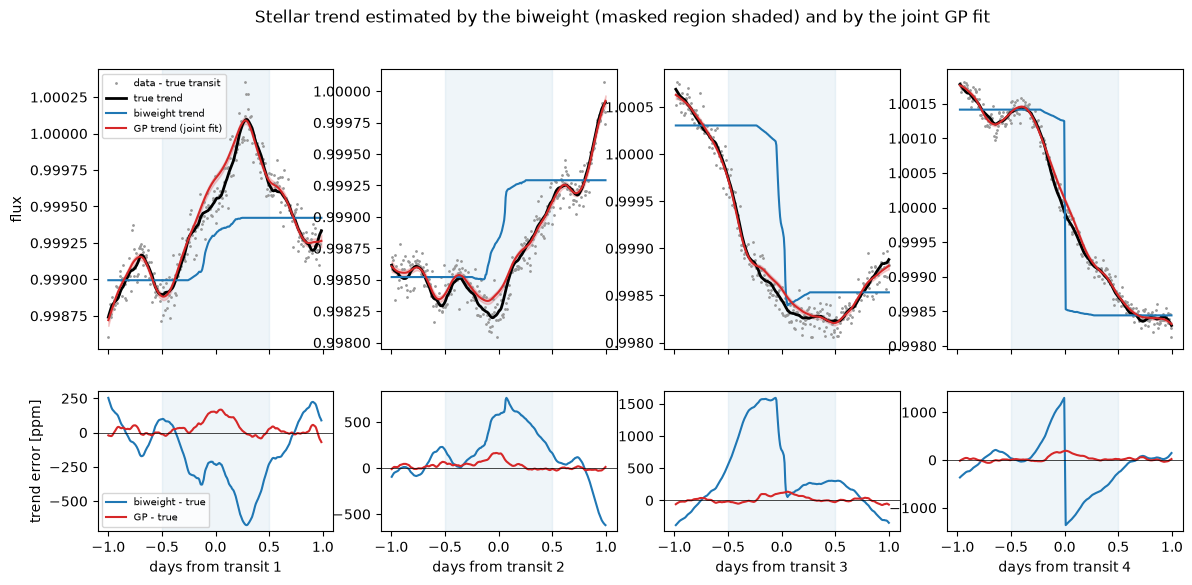

trend error inside the masked regions: biweight rms 643 ppm, GP rms 60 ppm


In [8]:
# the GP's trend: its posterior mean given the best-fit transit model (Kalman filter + smoother)
best = R["GP, moon"]["sampler"].parameters()
L_gp = R["GP, moon"]["sampler"].likelihood
f_best = model_flux(L_gp, best)
mu_gp, sd_gp = gp.predict(time, flux - f_best, flux_err)

fig, axs = plt.subplots(2, 4, sharex=True, figsize=(14, 6), gridspec_kw=dict(height_ratios=[2, 1]))
for k in range(4):
    m = np.abs(time - t_tr[k]) < 1.0
    x = time[m] - t_tr[k]
    ax = axs[0, k]
    ax.plot(x, flux[m] - flux_model[m] + 1, ".", ms=2, color="0.6", label="data - true transit")
    ax.plot(x, 1 + trend_true[m], color="k", lw=2, label="true trend")
    ax.plot(x, trend_bw[m], color="C0", label="biweight trend")
    ax.plot(x, 1 + mu_gp[m], color="C3", label="GP trend (joint fit)")
    ax.fill_between(x, 1 + mu_gp[m] - sd_gp[m], 1 + mu_gp[m] + sd_gp[m], color="C3", alpha=0.2)
    ax.axvspan(-MASK_HALF, MASK_HALF, color="C0", alpha=0.07)
    ax2 = axs[1, k]
    ax2.plot(x, 1e6 * (trend_bw[m] - 1 - trend_true[m]), color="C0", label="biweight - true")
    ax2.plot(x, 1e6 * (mu_gp[m] - trend_true[m]), color="C3", label="GP - true")
    ax2.axhline(0, color="k", lw=0.5)
    ax2.axvspan(-MASK_HALF, MASK_HALF, color="C0", alpha=0.07)
    ax2.set_xlabel(f"days from transit {k + 1}")
axs[0, 0].set_ylabel("flux"); axs[1, 0].set_ylabel("trend error [ppm]")
axs[0, 0].legend(fontsize=7); axs[1, 0].legend(fontsize=7)
plt.suptitle("Stellar trend estimated by the biweight (masked region shaded) and by the joint GP fit")
plt.show()
m_all = mask
print(f"trend error inside the masked regions: biweight rms {1e6 * np.nanstd((trend_bw - 1 - trend_true)[m_all]):.0f} "
      f"ppm, GP rms {1e6 * np.std((mu_gp - trend_true)[m_all]):.0f} ppm")

**Top row:** the data minus the true transit, the true stellar trend (black), the biweight's trend (blue) and the
GP's trend from the joint fit (red, its posterior mean given the best-fit planet+moon model). **Bottom row:** each
estimate minus the truth. The biweight's trend jumps at mid-transit and is wrong by up to 1500 ppm inside the
shaded masks. The GP follows the star through the transit (60 ppm rms), because it sees the data inside the mask
and models the transit at the same time.

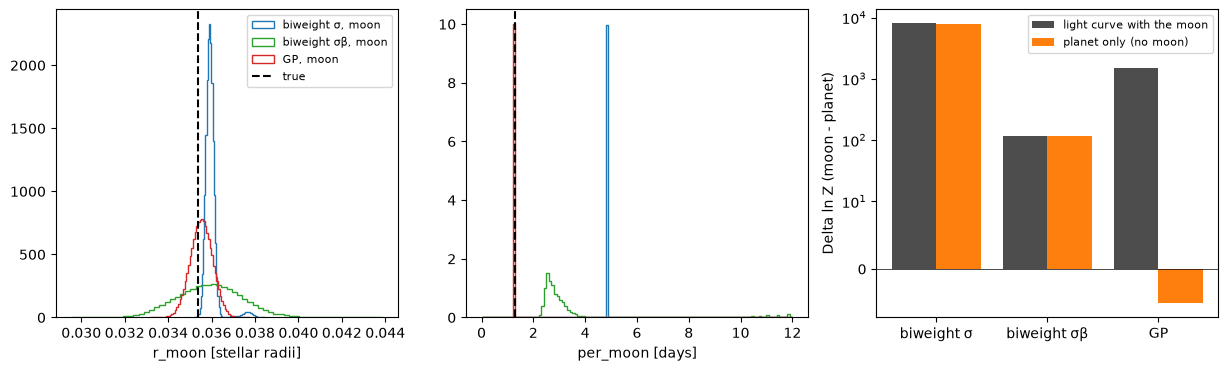

In [9]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4))
for (k, r), c in zip([(k, r) for k, r in R.items() if "no moon" not in k], ["C0", "C2", "C3"]):
    i_r = list(r["paramnames"]).index("r_moon"); i_p = list(r["paramnames"]).index("per_moon")
    axs[0].hist(r["samples"][:, i_r], bins=60, histtype="step", color=c, density=True, label=k)
    axs[1].hist(r["samples"][:, i_p], bins=np.linspace(0, 12, 121), histtype="step", color=c, density=True, label=k)
axs[0].axvline(truth["r_moon"], color="k", ls="--", label="true"); axs[1].axvline(truth["per_moon"], color="k", ls="--")
axs[0].set_xlabel("r_moon [stellar radii]"); axs[1].set_xlabel("per_moon [days]")
axs[0].legend(fontsize=8)
names = list(R)
x = np.arange(3)
dl_m = [R[n]["dlogz"] for n in names if "no moon" not in n]
dl_0 = [R[n]["dlogz"] for n in names if "no moon" in n]
axs[2].bar(x - 0.2, dl_m, 0.4, label="light curve with the moon", color="0.3")
axs[2].bar(x + 0.2, dl_0, 0.4, label="planet only (no moon)", color="C1")
axs[2].set_yscale("symlog", linthresh=10); axs[2].axhline(0, color="k", lw=0.5)
axs[2].set_xticks(x); axs[2].set_xticklabels(["biweight σ", "biweight σβ", "GP"])
axs[2].set_ylabel("Delta ln Z (moon - planet)"); axs[2].legend(fontsize=8)
plt.show()

**Left and middle:** the posteriors of the moon's radius and period in the light curve with the moon (dashed: the
truth). Only the GP gets the period. Most of the biweight σ posterior lies beyond the 12-day range shown (median
24 d), and the σβ posterior is a broad hump at the wrong period. **Right:** the Bayes factors of all six fits. Only
the GP separates the light curve with the moon from the one without it.

## 7. Run time: biweight vs GP

In [10]:
print(f"{'fit':24s} {'planet+moon fit':>16s} {'calls':>9s} {'calls/s':>9s}")
for k, r in R.items():
    print(f"{k:24s} {r['wall']:14.0f} s {r['ncall'] / 1e9:7.2f} G {r['ncall'] / r['wall'] / 1e6:7.1f} M")

fit                       planet+moon fit     calls   calls/s
biweight σ, moon                   1546 s   13.47 G     8.7 M
biweight σβ, moon                  2918 s   28.00 G     9.6 M
GP, moon                            381 s    2.34 G     6.1 M
biweight σ, no moon                 311 s    2.99 G     9.6 M
biweight σβ, no moon                200 s    2.01 G    10.1 M
GP, no moon                         497 s    2.48 G     5.0 M


**How the run time changes from biweight to GP**

- **Per likelihood call** the GP is more expensive. On the GPU (RTX 5060) a call takes ~1.7x as long as the
  white-noise call: the Kalman filter steps through the cadences of each transit window, while the white-noise
  likelihood only sums them. During these fits the GPU did 5–6 M GP calls per second against 9–10 M white-noise
  calls. On the CPU the extra cost is smaller, 15 μs against 11 μs per call on this light curve (+40 %).
- **Per fit** the GP was not slower here: 381 s and 497 s for the planet+moon fit, against 200–2918 s for the
  biweight fits. The GP fits needed fewer likelihood calls (2.3–2.5 G, against 2.0–28 G). The biweight fits fit the
  wrong noise model, and the sampler escalated them to 1000–2000 live points and up to 256 chain steps. A fit whose
  noise model matches the data converges sooner.
- **Hyperparameters:** `GP.fit` takes milliseconds (5.9 ms here) and is done once per light curve, before the fit.

Where the biweight's noise model happens to fit (a quiet star, a short mask), expect the GP to cost ~1.4–1.7x the
white-noise fit per call. Where it does not, the GP fit is the cheaper one, and it is the one that gives the right
answer.

## 8. On the CPU

Everything above works on the CPU too: `NestedSampler(..., device="cpu")`, or leave out `device` (the CPU is the
default). The GP likelihoods of the two devices agree to ~10⁻³ nats. A CPU fit of the same kind of light curve gave
ln Z −780.33 ± 0.17 against −780.56 ± 0.18 on the GPU (Δln Z 1406.72 against 1406.50).

## Summary

- `Likelihood(time, flux, flux_err, ..., gp=GP.fit(time, flux, flux_err, mask=mask))` fits the transit and the
  stellar variability together on the **raw** light curve. The hyperparameters come from the out-of-transit data and
  are fixed during the fit.
- On a star with variability on the moon's time scale, a masked biweight leaves trends in the transit that look
  like a moon. The GP finds the real moon, with the right period, and no moon where there is none.
- The GP is opt-in: without `gp=` Pandora's likelihood is unchanged. It is new and experimental. Check
  the GP's hyperparameters (`repr(gp)`) and the trend it implies (`gp.predict`) on your own light curve.